# 01 QPSK 数据发送与立即接收

承接 `01_module_verify`（LMK / SYSREF / DAC ADC 初始化）与 `02_tx_tone_loopback`（单音环回验证）。
本 notebook 把"单音"换成"已知数据"，走完全一样的一条硬件路径：

```
已知比特 → Gray QPSK 映射 → RRC 成型 → 加 ZC 前导组帧 → 拼成一次突发
        → DMA(MM2S) 发送 → 立即 DMA(S2MM) 整包抓回 → 存盘
```

**本 notebook 只负责"发"和"抓"，不做解调。** 解调在 `04_qpsk_demod`，一致性判定在 `05_qpsk_verify`。

三个 nb 之间通过 `.npz` 传递，所以可以单独重跑任意一个。

| 参数 | 值 | 说明 |
|---|---|---|
| 每符号样点 SPS | 8 | 字率 256 MHz → 符号率 32 MBaud |
| 成型滤波 | RRC，α=0.35，span=6 | 收发各一次，总响应为升余弦 |
| 前导 | 64 符号 ZC，root=25 | 恒包络、理想周期自相关，用于定时与频偏估计 |
| 数据 | 1024 比特 / 帧，共 9 帧 | 9 种不同图样，覆盖极端与随机 |

> **与 01 的关系**：`01_module_verify` 跑完直接往下跑本册即可，不需要重启内核或重配任何东西 ——
> 第 4 节会自己探测 PL 里的位流与 RFDC 状态：已是 v106 就**承接**（不重下），是 01 的 `soc_test`
> （32 位 MM）就按 v106 基准**切换**过来。**位流统一以 `v106/soc.bit` 为准。**
> 反过来，切到 v106 之后再回去跑 01 里那几项位流/DMA 检查，它会报"载入的不是它期望的那份"，
> 这是预期的，重跑 01 的第 1 节就能把 soc_test 下回去。

## 1　导入与参数

三个模块都在 `/home/xilinx/qpsk/`，与命令行版 `run_test.py` 完全同一份代码 ——
notebook 只是把它的内部步骤拆开、逐步显示，**不是另一套实现**。

In [1]:
import sys, os, time, json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

QPSK_DIR = "/home/xilinx/qpsk"
if QPSK_DIR not in sys.path:
    sys.path.insert(0, QPSK_DIR)

import qpsk_dsp as D
import qpsk_hw as H
import run_test as R

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
})

print("numpy    :", np.__version__)
print("qpsk_dsp :", D.__file__)
print("qpsk_hw  :", H.__file__)
print("SPS      :", D.SPS, "  Rolloff:", D.ROLLOFF, "  SPAN:", D.SPAN)
print("前导     : %d 符号 ZC (root=%d)，帧间保护 %d 符号"
      % (D.N_PRE, D.ZC_ROOT, D.GUARD_SYM))

NPZ_TX = "/home/xilinx/qpsk/qpsk_03_capture.npz"

N_BITS   = 1024      # 每帧比特数（必须是偶数）
N_FRAMES = 9         # 帧数
SEED     = 300       # 数据种子
PEAK     = 0.45      # 发送满量程比例（0.45 留 6.9 dB 余量，防 DAC 削顶）
SPS      = D.SPS

numpy    : 1.26.4
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
qpsk_hw  : /home/xilinx/qpsk/qpsk_hw.py
SPS      : 8   Rolloff: 0.35   SPAN: 6
前导     : 64 符号 ZC (root=25)，帧间保护 16 符号


## 2　生成 9 种已知数据图样

刻意选极端图样，因为它们各自会暴露一类问题：

| 图样 | 会暴露什么 |
|---|---|
| `zeros` / `ones` | 恒包络、单点星座 —— 直流偏移、载波泄漏敏感 |
| `alt`（0101…） | 符号在 ±45° 之间跳，频谱最靠边，成型滤波滚降不足会看出来 |
| `aa` / `55` | 字节对齐的周期图样，用来验证"比特→符号"的分组边界没错半个符号 |
| `cnt` | 递增字节，全 256 种组合都出现，覆盖所有 4 个星座点 |
| `prbs9` | 伪随机，统计特性接近真实业务数据 |
| `onehot` | 只有第 1 位为 1 —— 任何整体错位都会让它全错 |

之前踩过的坑就在这里：`aa`/`55`/`cnt` 早期返回的是**字节值**（170/85/0…255）而不是比特 0/1，
送进 `1-2*b` 后符号幅度飞到 208，星座完全散掉。现在 `make_bits` 里用 `np.unpackbits` 展开成比特，
`mod_qpsk` 里也加了断言挡住非比特输入。

In [2]:
frames    = R.build_payload_set(N_BITS, N_FRAMES, SEED)
tags      = [t for t, _ in frames]
bits_list = [b for _, b in frames]

print("%-9s %8s %8s %8s %8s   %s" %
      ("图样", "比特数", "0 的占比", "唯一值", "帧符号数", "前 24 比特"))
print("-" * 92)
for t, b in frames:
    print("%-9s %8d %8.3f %8d %10d   %s"
          % (t, len(b), 1.0 - b.mean(), len(np.unique(b)), len(b) // 2,
             "".join(str(int(x)) for x in b[:24])))

bad = [t for t, b in frames if b.max() > 1]
print()
print("比特范围检查:", "全部 ∈ {0,1} OK" if not bad else "⚠ 非比特数组: %s" % bad)

图样             比特数    0 的占比      唯一值     帧符号数   前 24 比特
--------------------------------------------------------------------------------------------
rand          1024    0.485        2        512   011010111111100101110100
zeros         1024    1.000        1        512   000000000000000000000000
ones          1024    0.000        1        512   111111111111111111111111
alt           1024    0.500        2        512   010101010101010101010101
aa            1024    0.500        2        512   101010101010101010101010
55            1024    0.500        2        512   010101010101010101010101
cnt           1024    0.562        2        512   000000000000000100000010
prbs9         1024    0.500        2        512   000001111011111000101110
onehot        1024    0.999        2        512   010000000000000000000000

比特范围检查: 全部 ∈ {0,1} OK


## 3　基带生成：QPSK 映射 → RRC 成型 → 组帧

**映射规则**（Gray 编码，与 04/05 完全一致，改动必须同步三处）：

```
b0 = 0 → I = +0.707      b0 = 1 → I = -0.707
b1 = 0 → Q = +0.707      b1 = 1 → Q = -0.707
```

即 `s = (1-2*b0)/√2 + j*(1-2*b1)/√2`，四个点落在 ±45°。

**组帧结构**：`[64 符号 ZC 前导][1024 符号数据][16 符号零保护]`，9 帧首尾相接，外面再各留 64 符号静默。

**归一化按 RMS 而不是峰值** —— 这点很重要：`zeros`/`ones` 是恒包络（PAPR≈0），随机 QPSK 的 PAPR≈6 dB。
若按全突发峰值归一，随机帧的电平会被压到 1/10，突发定位的块能量阈值就会漏掉它们。

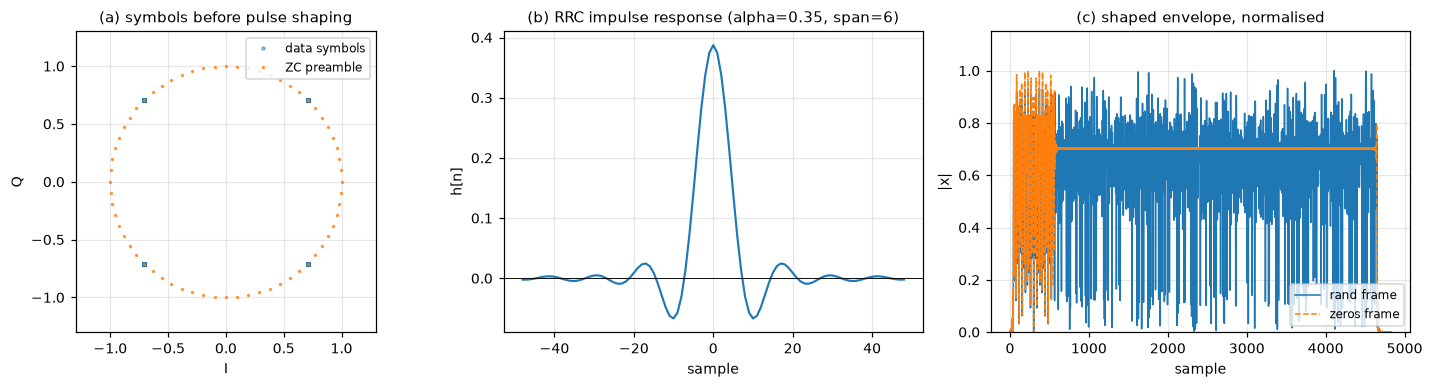

In [3]:
h = D.rrc_filter(SPS)

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))

# (a) 单帧符号级星座（前导 + 数据）
s0 = D.frame_symbols(bits_list[0])
ax[0].plot(s0[D.N_PRE:D.N_PRE + 512].real, s0[D.N_PRE:D.N_PRE + 512].imag,
           ".", ms=4, alpha=0.45, label="data symbols")
ax[0].plot(s0[:D.N_PRE].real, s0[:D.N_PRE].imag, ".", ms=2.5,
           color="tab:orange", alpha=0.7, label="ZC preamble")
ax[0].set_title("(a) symbols before pulse shaping")
ax[0].set_xlabel("I"); ax[0].set_ylabel("Q")
ax[0].set_aspect("equal"); ax[0].legend(loc="upper right")
ax[0].set_xlim(-1.3, 1.3); ax[0].set_ylim(-1.3, 1.3)

# (b) RRC 冲激响应
n = np.arange(len(h)) - (len(h) - 1) / 2
ax[1].plot(n, h, lw=1.4)
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_title("(b) RRC impulse response (alpha=%.2f, span=%d)"
                % (D.ROLLOFF, D.SPAN))
ax[1].set_xlabel("sample"); ax[1].set_ylabel("h[n]")

# (c) 成型后单帧包络（看 zeros 帧 vs 随机帧的差异）
for k, ls in ((0, "-"), (1, "--")):
    ps = D.pulse_shape(D.frame_symbols(bits_list[k]), h, SPS)
    ax[2].plot(np.abs(ps) / np.abs(ps).max(), ls, lw=1.0,
               label="%s frame" % tags[k])
ax[2].set_title("(c) shaped envelope, normalised")
ax[2].set_xlabel("sample"); ax[2].set_ylabel("|x|")
ax[2].legend(loc="lower right")
ax[2].set_ylim(0, 1.15)

plt.tight_layout(); plt.show()

突发基带     : 43648 点 (0.170 ms @ 256 MHz 字率)
前静默 lead  : 512 点
每帧样点     : 4736  (= 592 符号 × 8)
总符号数     : 5456

有效段 RMS   : 0.2368  (peak 设定 0.45)
峰值         : 0.3734  → int16 幅值 12235  (满量程 32767)
PAPR         : 3.95 dB
削顶样点     : 0  (必须为 0)
发送字数     : 43648  (0.2 MB)


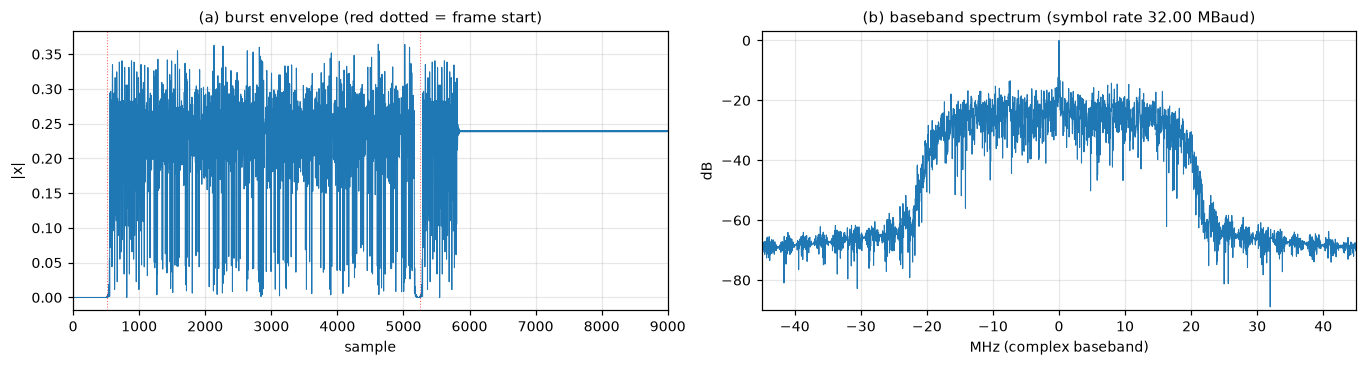

In [4]:
bb, lead, spf_smp = D.build_burst(bits_list, h, SPS, peak=PEAK)
words = D.to_words(bb)

print("突发基带     : %d 点 (%.3f ms @ 256 MHz 字率)" % (len(bb), len(bb) / 256e6 * 1e3))
print("前静默 lead  : %d 点" % lead)
print("每帧样点     : %d  (= %d 符号 × %d)" % (spf_smp, spf_smp // SPS, SPS))
print("总符号数     : %d" % (len(bb) // SPS))
print()
act = bb[np.abs(bb) > 1e-12]
print("有效段 RMS   : %.4f  (peak 设定 %.2f)" % (np.sqrt(np.mean(np.abs(act) ** 2)), PEAK))
print("峰值         : %.4f  → int16 幅值 %d  (满量程 32767)"
      % (np.max(np.abs(bb)), int(np.max(np.abs(bb)) * 32767)))
print("PAPR         : %.2f dB" % (20 * np.log10(np.max(np.abs(act)) / np.sqrt(np.mean(np.abs(act) ** 2)))))
print("削顶样点     : %d  (必须为 0)" % int(np.sum(np.abs(bb) * 32767 >= 32767)))
print("发送字数     : %d  (%.1f MB)" % (len(words), words.nbytes / 1e6))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.4))
m = min(len(bb), 9000)
ax[0].plot(np.abs(bb[:m]), lw=0.7)
for k in range(N_FRAMES):
    ax[0].axvline(lead + k * spf_smp, color="r", ls=":", lw=0.7, alpha=0.6)
ax[0].set_title("(a) burst envelope (red dotted = frame start)")
ax[0].set_xlabel("sample"); ax[0].set_ylabel("|x|"); ax[0].set_xlim(0, m)

X = np.fft.fftshift(np.fft.fft(bb[lead:lead + spf_smp * N_FRAMES], 8192))
f = (np.arange(len(X)) - len(X) // 2) / len(X) * 256e6 / SPS * SPS / 1e6
ax[1].plot(f, 20 * np.log10(np.abs(X) / np.abs(X).max() + 1e-12), lw=0.7)
ax[1].set_title("(b) baseband spectrum (symbol rate %.2f MBaud)"
                % (256e6 / SPS / 1e6))
ax[1].set_xlabel("MHz (complex baseband)"); ax[1].set_ylabel("dB")
ax[1].set_ylim(-90, 3); ax[1].set_xlim(-45, 45)
plt.tight_layout(); plt.show()

## 4　承接 01 的环境，自检环回

### 位流以 v106 为准

`01_module_verify` 载入的是 `/home/xilinx/soc_test/soc.bit`（**32 位** MM 构建），
本节用的是 `/home/xilinx/jupyter_notebooks/v106/soc.bit`（**128 位** MM）。两者的 IP 清单、
基地址、`C_FRAME_LEN` 完全一致，只有 DMA 存储器侧位宽不同 —— 而 32 位版本在 256 MHz 字率下
DMA 读密度是 100%，DDR 一有刷新抖动就在 TX 侧插入保持段，QPSK 会直接误码。
所以**位流以 v106 为准**，01 那边载入别的构建时本节会切过来。

`open_clean_loopback()` 的第一步是**探路**，不是无条件重来：

| PL 里的现状 | 动作 | 耗时 |
|---|---|---|
| 已经是 v106 | `Overlay(bit, download=False)`，只解析 hwh 拿地址表，不重下 | ~1.0 s |
| 是别的位流（如 01 的 soc_test） | 载入 v106 覆盖 | ~1.9 s |

`PL.bitfile_name` 由 PYNQ 的 pl_server 统一记账，**跨 kernel 进程有效** —— 01 在它自己的
notebook 里下过位流，03 这边看得见，不用靠变量传递。

RFDC 同理：同进程内 `is_ready()` 已为真就不再 `deinit/init`（二次 StartUp 会把 ADC tile
拖到 `0xC`，这是 01 §3 的实测结论）；只有位流重下过才重建。NCO 也先读回，已是 1000 MHz
就一个字都不写，避免无谓地改掉 01 的寄存器状态。

### 为什么要自检波峰因数

本板每次下载 bitstream 后，ADC 有相当概率**只回 I 通道**（虚部恒为 0）。
此时收到的是实信号 `s + conj(s)`，包络周期性过零、波峰因数从 1.6 升到 3.4 以上，
而帧起点、帧间距、相关峰全都"正常"—— 只有解调结果全错。这个现象极容易被误判成 DSP 有 bug。

恢复手段是 `rf_reinit()`：只重跑 RFDC 的 deinit/init/NCO，约 0.1 s，
比整片重下 bitstream（约 2 s）快 20 倍，实测一次即恢复。

In [5]:
t_open = time.time()
lb, n_try, cf = R.open_clean_loopback(words, len(bb))
env = lb.env

print()
print("位流     : %s" % env["bit_label"])
if env["reused"]:
    print("           承接 PL 里已载入的同一份，本次未重下")
else:
    print("           已按 v106 基准载入（PL 里原来是 %s）" % env["prev_label"])
print("RFDC     : %s" % env["rf_state"])
print("环回就绪 : 自检 %d 次，波峰因数 %.2f（阈值 %.1f），耗时 %.1f s"
      % (n_try, cf, R.CF_CLEAN, time.time() - t_open))
print("采样率   : RF %.1f MSPS → 字率 %.3f MHz → 符号率 %.3f MBaud"
      % (lb.fs_rf, lb.fs_word / 1e6, lb.fs_word / SPS / 1e6))

print()
st = lb.status()
for k in ("DAC", "ADC"):
    v = st[k]
    print("%s0 : enabled=%s  state=0x%X  PLL=%s"
          % (k, v.get("enabled"), v.get("state", -1), v.get("pll")))
ok_state = (st["DAC"].get("state") == 0xF) and (st["ADC"].get("enabled") == 1)
print()
print("状态判据 :", "OK（DAC FULL + ADC 使能）" if ok_state
      else "⚠ 异常 —— 先按 01 检查 LMK/SYSREF，否则后面的结果不可信")

  overlay 承接 1065 ms，5 个 IP
  DAC0 NCO 已是 1000.000 MHz，沿用
  ADC0 NCO 已是 1000.000 MHz，沿用
  环回自检  0（首次建立）：波峰因数 1.66  OK

位流     : v106/soc.bit
           承接 PL 里已载入的同一份，本次未重下
RFDC     : init()
环回就绪 : 自检 1 次，波峰因数 1.66（阈值 2.5），耗时 2.4 s
采样率   : RF 4096.0 MSPS → 字率 256.000 MHz → 符号率 32.000 MBaud

DAC0 : enabled=True  state=0xF  PLL=1
ADC0 : enabled=True  state=0xF  PLL=1

状态判据 : OK（DAC FULL + ADC 使能）


## 5　发送 → 立即接收

时序上先挂接收（S2MM 就绪）、再启动发送（MM2S），这样突发不会被切头。
接收端一次抓满 `C_FRAME_LEN` = 4194303 个字（约 16.4 ms），远大于突发本身，
所以抓到的数据里包含"静默 + 完整突发 + 静默"三段，04 会自己定位。

`prewarm` 那一发是给 DMA 通路的预热 —— 第一次收发常因 cache / AXI 通路未热而丢头，
这与 02 里遇到的现象一致。

In [6]:
t0 = time.time()
G = lb.loop(words)
t_cap = time.time() - t0

x_raw = D.from_words(G["w"])
n_real = G["n"]
x = x_raw[:n_real] if n_real else x_raw

print("DMA 请求 %d 字，实际收到 %d 字 (%.2f ms)" % (G["req"], n_real, n_real / lb.fs_word * 1e3))
print("TX 完成 %s，TX 状态 0x%X，发送→收齐 GAP %.0f us"
      % ("是" if G["tx_ok"] else "否", G["tx_sr"], G["gap_us"]))
print("墙钟耗时 %.0f ms" % (t_cap * 1e3))
print()
print("收到样点    : %d  (实部范围 %+d..%+d, 虚部范围 %+d..%+d)"
      % (len(x), int(x.real.min()), int(x.real.max()),
         int(x.imag.min()), int(x.imag.max())))
print("虚部能量占比: %.3f   (正常 QPSK 应≈0.5，若≈0 说明 ADC 只回了 I 通道)"
      % (np.mean(x.imag ** 2) / max(np.mean(np.abs(x) ** 2), 1e-9)))

DMA 请求 4194303 字，实际收到 4194299 字 (16.38 ms)
TX 完成 是，TX 状态 0x1002，发送→收齐 GAP 75 us
墙钟耗时 373 ms

收到样点    : 4194299  (实部范围 -4755..+4737, 虚部范围 -4733..+4703)
虚部能量占比: 0.500   (正常 QPSK 应≈0.5，若≈0 说明 ADC 只回了 I 通道)


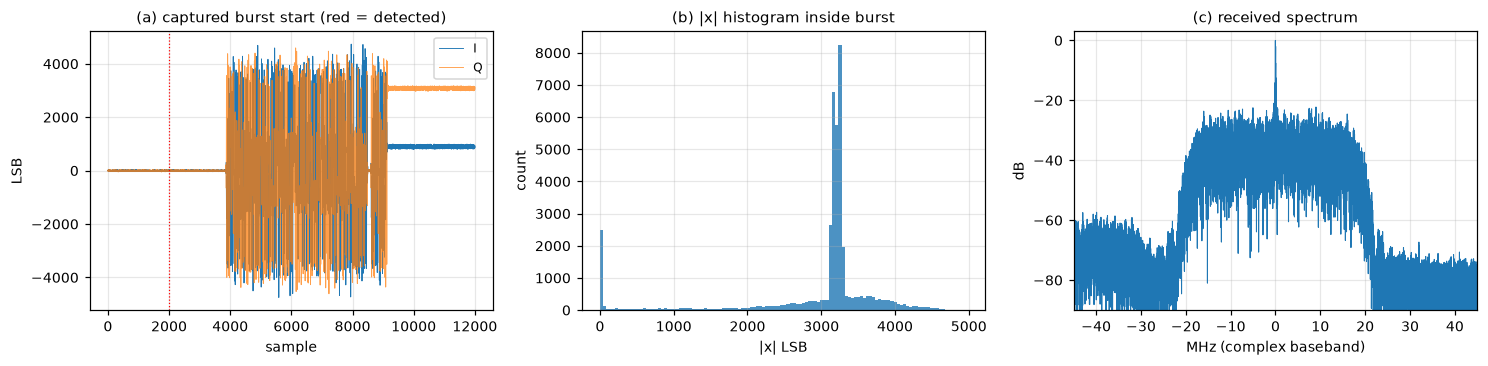

突发区间 [18432, 64512)，长 46080 点（发送 43648 点）
波峰因数 1.66  →  单边带干净


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13.6, 3.4))

# (a) 突发所在的一段时域
a, b_ = D.find_active(x)
lo = max(0, a - 2000)
hi = min(len(x), lo + 12000)
ax[0].plot(x.real[lo:hi], lw=0.6, label="I")
ax[0].plot(x.imag[lo:hi], lw=0.6, alpha=0.75, label="Q")
ax[0].axvline(a - lo, color="r", ls=":", lw=0.8)
ax[0].set_title("(a) captured burst start (red = detected)")
ax[0].set_xlabel("sample"); ax[0].set_ylabel("LSB"); ax[0].legend(loc="upper right")

# (b) 幅度直方图：干净 QPSK 应集中在 ~0.55 满量程
ax[1].hist(np.abs(x[a:a + len(bb)]), bins=120, color="tab:blue", alpha=0.8)
ax[1].set_title("(b) |x| histogram inside burst")
ax[1].set_xlabel("|x| LSB"); ax[1].set_ylabel("count")

# (c) 接收谱（看是否单边带）
seg = x[a:a + len(bb)]
X = np.fft.fftshift(np.fft.fft(seg[:1 << 16], 1 << 16))
fq = (np.arange(len(X)) - len(X) // 2) / len(X) * lb.fs_word / 1e6
ax[2].plot(fq, 20 * np.log10(np.abs(X) / np.abs(X).max() + 1e-12), lw=0.7)
ax[2].set_title("(c) received spectrum")
ax[2].set_xlabel("MHz (complex baseband)"); ax[2].set_ylabel("dB")
ax[2].set_ylim(-90, 3); ax[2].set_xlim(-45, 45)

plt.tight_layout(); plt.show()

print("突发区间 [%d, %d)，长 %d 点（发送 %d 点）" % (a, b_, b_ - a, len(bb)))
print("波峰因数 %.2f  →  %s"
      % (cf, "单边带干净" if cf < R.CF_CLEAN else "⚠ 双边带污染"))

## 6　存盘，交给 04 解调

存的是**原始字 + 真值比特 + 全部参数**，一个字都不做处理 —— 这样 04 的每一步都能从原始数据重算，
出问题时可回退到任意环节复核。

In [8]:
payload = dict(
    words=np.asarray(G["w"], dtype=np.uint32),
    n_real=np.int64(n_real),
    n_bits=np.int64(N_BITS), n_frames=np.int64(N_FRAMES),
    sps=np.int64(SPS), peak=np.float64(PEAK),
    lead=np.int64(lead), spf_smp=np.int64(spf_smp), bb_len=np.int64(len(bb)),
    fs_word=np.float64(lb.fs_word),
    crest=np.float64(cf), n_try=np.int64(n_try),
)
for i, (tag, bits) in enumerate(frames):
    payload["truth_%d" % i] = np.asarray(bits, dtype=np.uint8)
payload["tags"] = np.array(tags, dtype="U16")

np.savez_compressed(NPZ_TX, **payload)
print("已保存 %s  (%.2f MB)" % (NPZ_TX, os.path.getsize(NPZ_TX) / 1e6))
print()
print("内容：")
print("  words        %s uint32  （4.19 M 字的原始接收缓冲）" % (payload["words"].shape,))
print("  n_real, fs_word, sps, lead, spf_smp, bb_len  → 04 定位用")
print("  truth_0..8   （9 帧真值比特，各 %d 位）" % N_BITS)
print()
print("下一步：打开 04_qpsk_demod.ipynb")

已保存 /home/xilinx/qpsk/qpsk_03_capture.npz  (8.13 MB)

内容：
  words        (4194303,) uint32  （4.19 M 字的原始接收缓冲）
  n_real, fs_word, sps, lead, spf_smp, bb_len  → 04 定位用
  truth_0..8   （9 帧真值比特，各 1024 位）

下一步：打开 04_qpsk_demod.ipynb


---
## 附：与 02 单音验证的对应关系

| 02 里的动作 | 03 里的对应 | 说明 |
|---|---|---|
| `dac.set_nco` / `adc.set_nco` | `Loopback.__init__` 里 `xrfdc.set_nco_mhz(...)` | 同一个 API，1000 MHz 上下混频互相抵消 |
| 写 DAC 缓冲 | `lb.loop(words)` 内部 `MM2S` 单次突发 | 长度 = 突发字数，不是满包 |
| 启动接收 | 同上 `S2MM` 整包（4194303 字） | 先挂接收再发，避免切头 |
| `np.frombuffer(...).view(int16)` 解包 I/Q | `D.from_words` | 低 16 位 I，高 16 位 Q |

如果 02 里您用的是自封装的类而不是本目录的 `qpsk_hw.py`，只要把 `Loopback` 换成您的实现、
并保持 `loop(words) -> {"w", "n", "fs"}` 这个契约，后面两个 notebook 不用改。